# Stochastic Day-Ahead Energy Planning for a Solar–Battery Campus Microgrid
**Course:** 21AIE321T Stochastic Decision Making · **Assignment IV (CLA-2)** · SRM IST Tiruchirappalli · SDG 9 (Target 9.5)

**Problem.** A campus microgrid (600 kWp PV, 800 kWh battery, 450 kW grid connection) must commit to **hourly day-ahead purchases before tomorrow's sunshine and load are known**.
Shortfalls are bought in real time at 2× price; surpluses are resold at ₹3/kWh. We build a **two-stage stochastic LP** (Sample Average Approximation), a **mean-CVaR** variant, and compare with a **deterministic mean-forecast** baseline.

This notebook reproduces the headline results of the report (full experiments: `python -m src.run_experiments`).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from src.microgrid import *
pd.set_option('display.width', 170); pd.set_option('display.max_columns', None)
sy, ws = System(), WeatherSpec()
print(pd.read_csv('../results/table0_system_parameters.csv').to_string(index=False))

                      parameter     value
              PV capacity (kWp)     600.0
           Battery energy (kWh)     800.0
             Battery power (kW)     200.0
             One-way efficiency      0.92
                        Min SOC       0.1
           Grid connection (kW)     450.0
     Real-time price multiplier       2.0
Export / resale price (INR/kWh)       3.0
   Value of lost load (INR/kWh)      60.0
         Battery wear (INR/kWh)       1.2
     DA price min/max (INR/kWh) 5.0 / 9.5


## 1. Data: 730 days of hourly PV output and load

In [2]:
h = pd.read_csv('../data/microgrid_history_hourly.csv')
PVh = h.pv_kw.values.reshape(-1, 24); LDh = h.load_kw.values.reshape(-1, 24)
print(h.head(8)); print('days:', len(PVh))
print(pd.read_csv('../results/table1_data_statistics.csv').to_string(index=False))
print('daily PV-load correlation: %.2f' % np.corrcoef(PVh.sum(1), LDh.sum(1))[0, 1])

         date  hour  pv_kw  load_kw
0  2024-01-01     0    0.0    207.7
1  2024-01-01     1    0.0    206.3
2  2024-01-01     2    0.0    192.7
3  2024-01-01     3    0.0    180.8
4  2024-01-01     4    0.0    193.9
5  2024-01-01     5    0.0    209.8
6  2024-01-01     6   42.4    242.7
7  2024-01-01     7  155.3    297.4
days: 730
weather_state  days  share_pct  pv_kwh_mean  pv_kwh_std  load_kwh_mean  peak_load_mean
        Sunny   383      52.47      3793.44      274.20        7698.92          436.73
Partly cloudy   227      31.10      2572.60      681.12        7238.78          409.74
     Overcast   120      16.44      1170.83      461.91        6785.98          385.87
     ALL DAYS   730     100.00      2982.69     1075.24        7405.76          419.98
daily PV-load correlation: 0.67


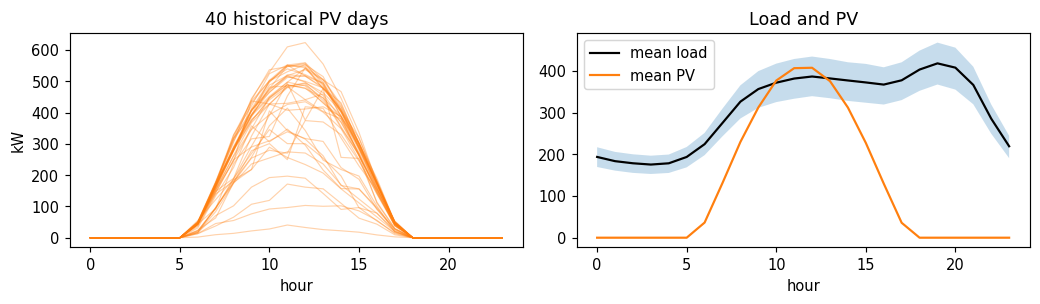

In [3]:
hrs = np.arange(24)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for j in range(40): ax[0].plot(hrs, PVh[j], alpha=.35, lw=.8, color='tab:orange')
ax[0].set_title('40 historical PV days'); ax[0].set_xlabel('hour'); ax[0].set_ylabel('kW')
ax[1].plot(hrs, LDh.mean(0), 'k', label='mean load'); ax[1].fill_between(hrs, np.quantile(LDh, .05, 0), np.quantile(LDh, .95, 0), alpha=.25)
ax[1].plot(hrs, PVh.mean(0), color='tab:orange', label='mean PV'); ax[1].legend(); ax[1].set_title('Load and PV'); ax[1].set_xlabel('hour')
plt.tight_layout(); plt.show()

## 2. Solve the two-stage stochastic programme (SAA, S = 300) and the deterministic baseline

In [4]:
PV_tr, LD_tr = smoothed_bootstrap(PVh, LDh, 300, np.random.default_rng(11))   # scenarios from history
x_sto, obj = solve_saa(PV_tr, LD_tr, sy, return_obj=True)
x_det = solve_saa(PVh.mean(0)[None], LDh.mean(0)[None], sy)
sched = pd.DataFrame({'DA price': DA_PRICE, 'mean load': LDh.mean(0), 'mean PV': PVh.mean(0), 'deterministic kWh': x_det, 'stochastic kWh': x_sto}, index=hrs)
print(sched.round(1).to_string())
print('\nTotal day-ahead purchase  deterministic: %.0f kWh   stochastic: %.0f kWh' % (x_det.sum(), x_sto.sum()))

    DA price  mean load  mean PV  deterministic kWh  stochastic kWh
0        5.0      193.8      0.0              193.8           237.4
1        5.0      183.7      0.0              183.7           217.2
2        5.0      178.6      0.0              178.6           209.9
3        5.0      175.5      0.0              359.3           204.4
4        5.0      178.5      0.0              178.5           209.0
5        5.0      193.7      0.0              393.7           323.5
6        6.5      224.5     36.3              188.2           186.1
7        6.5      275.4    131.4              144.0           137.8
8        6.5      326.5    229.9               96.6            76.2
9        6.5      356.7    312.5               44.2            14.7
10       6.0      372.0    377.0                0.0            38.5
11       6.0      381.9    406.8                0.0            17.2
12       6.0      386.8    407.7                0.0            30.1
13       6.0      382.1    375.6                

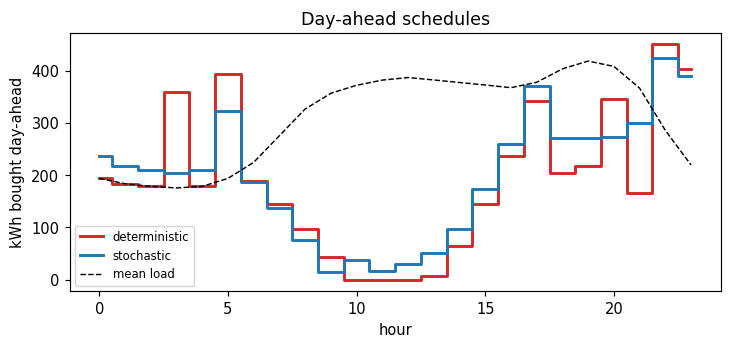

In [5]:
plt.figure(figsize=(8, 3.2))
plt.step(hrs, x_det, where='mid', color='tab:red', lw=2, label='deterministic'); plt.step(hrs, x_sto, where='mid', color='tab:blue', lw=2, label='stochastic')
plt.plot(hrs, LDh.mean(0), 'k--', lw=1, label='mean load'); plt.xlabel('hour'); plt.ylabel('kWh bought day-ahead'); plt.legend(fontsize=8); plt.title('Day-ahead schedules'); plt.show()

## 3. Out-of-sample evaluation (2,000 fresh days from the true process): cost, risk, VSS, EVPI

In [6]:
Tp, Tl, Tstate = sample_days(ws, 2000, np.random.default_rng(99))      # never used for fitting / optimisation
ev = Evaluator(sy)
c_sto, d_sto = ev.costs(x_sto, Tp, Tl, want_detail=True)
c_det, d_det = ev.costs(x_det, Tp, Tl, want_detail=True)
print(pd.DataFrame({'Deterministic': risk_summary(c_det), 'Stochastic': risk_summary(c_sto)}).T.round(0))
diff = c_det - c_sto; b = np.random.default_rng(5)
boot = [diff[b.integers(0, 2000, 2000)].mean() for _ in range(2000)]
print('\nVSS = %.1f INR/day (95%% CI %.1f .. %.1f) = %.2f%% of deterministic cost' % (diff.mean(), np.quantile(boot, .025), np.quantile(boot, .975), 100 * diff.mean() / c_det.mean()))
print('Stochastic plan cheaper on %.1f%% of days' % (100 * (diff > 0).mean()))
print('Real-time purchases: deterministic %.0f kWh/day -> stochastic %.0f kWh/day' % (d_det['rt_kwh'].mean(), d_sto['rt_kwh'].mean()))

                  mean     std      p50      p95      max   cvar90
Deterministic  34043.0  7017.0  31504.0  48528.0  65092.0  49184.0
Stochastic     33548.0  6249.0  30946.0  46996.0  63257.0  47641.0

VSS = 494.9 INR/day (95% CI 450.4 .. 541.4) = 1.45% of deterministic cost
Stochastic plan cheaper on 63.3% of days
Real-time purchases: deterministic 405 kWh/day -> stochastic 250 kWh/day


In [7]:
ws300 = wait_and_see(Tp[:300], Tl[:300], sy)
print('Wait-and-see cost (N=300): %.0f   ->   EVPI = %.0f INR/day  (about %.1fx the VSS)' % (ws300.mean(), (c_sto[:300] - ws300).mean(), (c_sto[:300] - ws300).mean() / diff.mean()))
names = ['Sunny', 'Partly cloudy', 'Overcast']
print(pd.DataFrame({'days': [int((Tstate == k).sum()) for k in range(3)], 'det cost': [c_det[Tstate == k].mean() for k in range(3)],
                    'stoch cost': [c_sto[Tstate == k].mean() for k in range(3)], 'saving': [(c_det - c_sto)[Tstate == k].mean() for k in range(3)]}, index=names).round(0))

Wait-and-see cost (N=300): 30136   ->   EVPI = 3222 INR/day  (about 6.5x the VSS)
               days  det cost  stoch cost  saving
Sunny          1044   29969.0     29858.0   111.0
Partly cloudy   628   35025.0     34443.0   582.0
Overcast        328   45132.0     43582.0  1549.0


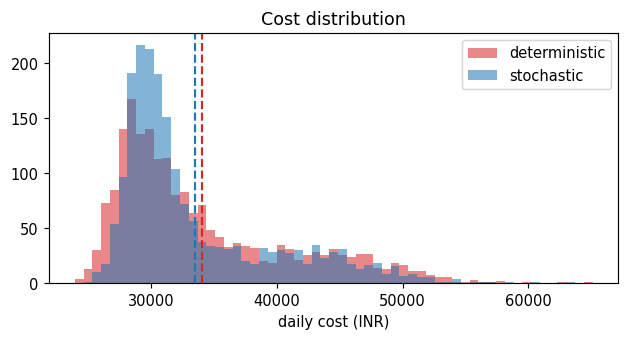

In [8]:
bins = np.linspace(min(c_sto.min(), c_det.min()), max(c_sto.max(), c_det.max()), 60)
plt.figure(figsize=(7, 3.1)); plt.hist(c_det, bins=bins, alpha=.55, color='tab:red', label='deterministic'); plt.hist(c_sto, bins=bins, alpha=.55, color='tab:blue', label='stochastic')
plt.axvline(c_det.mean(), color='tab:red', ls='--'); plt.axvline(c_sto.mean(), color='tab:blue', ls='--'); plt.xlabel('daily cost (INR)'); plt.legend(); plt.title('Cost distribution'); plt.show()

## 4. Risk-averse extension: mean-CVaR frontier

 lam  DA_kwh  mean_cost     std   cvar90
0.00 4815.21   33479.54 6130.71 47418.60
0.25 5591.43   34252.88 3720.75 42741.08
0.50 5834.53   34791.33 3174.51 41399.72
0.90 5981.38   35098.03 2990.49 41068.59


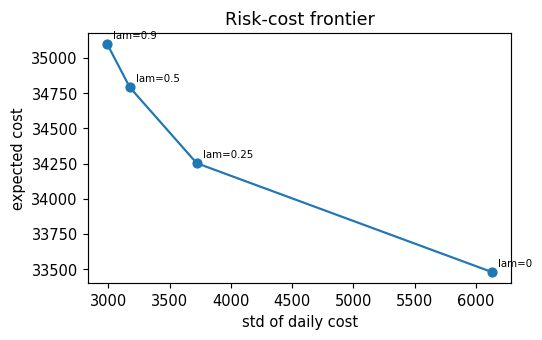

In [9]:
PVc, LDc = smoothed_bootstrap(PVh, LDh, 150, np.random.default_rng(21))
rows = []
for lam in [0, 0.25, 0.5, 0.9]:
    xc = solve_saa(PVc, LDc, sy, lam=lam); r = risk_summary(ev.costs(xc, Tp[:600], Tl[:600]))
    rows.append(dict(lam=lam, DA_kwh=xc.sum(), mean_cost=r['mean'], std=r['std'], cvar90=r['cvar90']))
cvd = pd.DataFrame(rows); print(cvd.round(2).to_string(index=False))
plt.figure(figsize=(5.2, 3.1)); plt.plot(cvd['std'], cvd.mean_cost, 'o-')
for _, r in cvd.iterrows(): plt.annotate('lam=%g' % r.lam, (r['std'], r.mean_cost), fontsize=7, xytext=(4, 4), textcoords='offset points')
plt.xlabel('std of daily cost'); plt.ylabel('expected cost'); plt.title('Risk-cost frontier'); plt.show()

## 5. Sensitivity: value of the stochastic solution vs real-time price multiplier

 rt_multiplier  stochastic  deterministic     VSS  VSS_pct
           1.0    30022.86       30022.58   -0.28    -0.00
           2.0    33355.57       33773.66  418.09     1.24
           3.0    34389.41       36292.84 1903.43     5.24
           4.0    34871.87       38811.98 3940.12    10.15


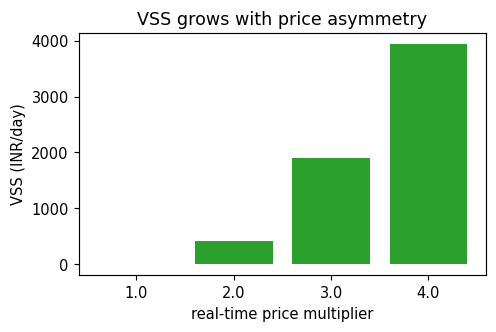

In [10]:
rows = []
for rho in [1.0, 2.0, 3.0, 4.0]:
    s2 = replace(sy, rt_premium=rho)
    Ph, Lh, _ = sample_days(ws, 365, np.random.default_rng(30)); P_, L_ = smoothed_bootstrap(Ph, Lh, 100, np.random.default_rng(31))
    xs = solve_saa(P_, L_, s2); xd = solve_saa(Ph.mean(0)[None], Lh.mean(0)[None], s2)
    tp, tl, _ = sample_days(ws, 300, np.random.default_rng(32)); e2 = Evaluator(s2)
    a, d_ = e2.costs(xs, tp, tl).mean(), e2.costs(xd, tp, tl).mean()
    rows.append(dict(rt_multiplier=rho, stochastic=a, deterministic=d_, VSS=d_ - a, VSS_pct=100 * (d_ - a) / d_))
sens = pd.DataFrame(rows); print(sens.round(2).to_string(index=False))
plt.figure(figsize=(5, 3)); plt.bar(sens.rt_multiplier.astype(str), sens.VSS, color='tab:green'); plt.xlabel('real-time price multiplier'); plt.ylabel('VSS (INR/day)'); plt.title('VSS grows with price asymmetry'); plt.show()

## 6. Conclusions (from the full run)
* **Cost:** ₹33,548/day (stochastic) vs ₹34,043/day (deterministic) → **VSS = ₹494.9/day (1.45%)**, 95 % CI ₹450–541.
* **Risk:** cost std ₹6,249 vs ₹7,017; worst-10 %-day average ₹47,641 vs ₹49,184.
* **Real-time purchases** fall from 405 to 250 kWh/day; the stochastic plan is cheaper on 63 % of days.
* **EVPI = ₹3,281/day** ≫ VSS: better forecasts are worth more than a better optimiser.
* VSS is ≈ 0 with no real-time premium and rises steeply with it; the plan loses if load falls 10 % below the training level (report §6.3).

The same numbers appear in `results/` and in the PDF report in `report/`.